In [2]:
import pandas as pd
import numpy as np

chosen_year = "2023"

market = pd.read_pickle(f"./labelled_market/{chosen_year}.pkl")


In [13]:
market['10 Day Avg Volume'] = market.groupby(level='Ticker')['Volume'].apply(lambda x: x.rolling(window=10).mean().shift(1)).reset_index(level=0, drop=True)
market['Prop 10 Day Avg Volume'] = market["Volume"] / market["10 Day Avg Volume"]


view_data = market[["Volume", "10 Day Avg Volume", "Prop 10 Day Avg Volume"]].groupby(level="Ticker").apply(lambda x: x)


market.mean()['Prop 10 Day Avg Volume']

np.float64(inf)

In [1]:
import statsmodels.api as sm
import numpy as np

independent = ["Prop 10 Day Avg Volume"]
dependent = ["Percent 2 Week Growth"]

data_wrangled = market.dropna(subset=[*independent, *dependent])


X = data_wrangled[independent].apply(pd.to_numeric, errors='coerce')
y = data_wrangled[dependent].apply(pd.to_numeric, errors='coerce')

# Align X and y to ensure they have the same indices and drop NaNs
X, y = X.align(y, join='inner', axis=0)

X = sm.add_constant(X)

# Convert to numpy arrays
X = np.asarray(X, dtype=np.float64)
y = np.asarray(y, dtype=np.float64)

print(sm.OLS(y, X).fit().summary())

results = sm.OLS(y, X).fit()


import matplotlib.pyplot as plt
plt.scatter(market_logs['Percent 1 Week Growth'], market_logs['Percent 1 to 2 Week Growth'])
fig = sm.graphics.abline_plot(model_results=results, color='red', ax=plt.gca())

NameError: name 'market' is not defined

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     11.74
Date:                Fri, 15 Nov 2024   Prob (F-statistic):           0.000611
Time:                        02:11:40   Log-Likelihood:             2.1798e+05
No. Observations:              119007   AIC:                        -4.359e+05
Df Residuals:                  119005   BIC:                        -4.359e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0024      0.000     21.273      0.0

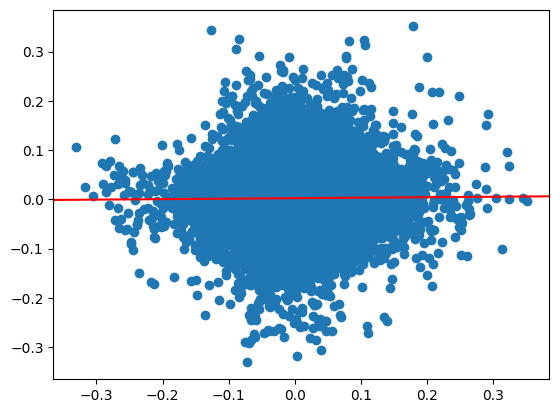

In [ ]:
# import statsmodels.api as sm
# import numpy as np



# data_wrangled = market_logs.dropna(subset=["Percent 1 Week Growth", "Percent 1 to 2 Week Growth"])


# X = data_wrangled["Percent 1 Week Growth"].apply(pd.to_numeric, errors='coerce')
# y = data_wrangled["Percent 1 to 2 Week Growth"].apply(pd.to_numeric, errors='coerce')

# # Align X and y to ensure they have the same indices and drop NaNs
# X, y = X.align(y, join='inner', axis=0)

# X = sm.add_constant(X)

# # Convert to numpy arrays
# X = np.asarray(X, dtype=np.float64)
# y = np.asarray(y, dtype=np.float64)

# print(sm.OLS(y, X).fit().summary())

# results = sm.OLS(y, X).fit()


# import matplotlib.pyplot as plt
# plt.scatter(market_logs['Percent 1 Week Growth'], market_logs['Percent 1 to 2 Week Growth'])
# fig = sm.graphics.abline_plot(model_results=results, color='red', ax=plt.gca())